# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [36]:
SOURCE_URL = "https://data.worldbank.org/indicator/SP.DYN.LE00.IN"       # the page or file you downloaded from
DOWNLOAD_DATE = "2026-11-07"    # YYYY-MM-DD
FILE_NAME = "data/wb_life_expectancy.csv"        # the file as saved in your repository's data/ folder

**Who collected it, for what purpose, what is missing and why?**

The World Bank publishes life expectancy and GDP per capita and the government health spending share in its World Development Indicators so people can compare countries and it last updated all three files on 8 October 2026 but it doesn't collect the data itself. The UN Population Division estimates life expectancy from death records and from surveys and models if a country doesn't keep records, and GDP per capita in constant 2021 PPP dollars comes from each country's national accounts and the International Comparison Program's price surveys so any country that doesn't publish accounts or take part in the surveys has no value. WHO collects the health spending share and UNDP estimates mean years of schooling for adults 25 and older from censuses and surveys for its Human Development Report 2025 but UNDP only covers countries so territories like Puerto Rico have no value, and I replaced the Kaggle file from my checkpoint post with these sources because the checkpoint feedback said its GDP doesn't match official figures.

### Load the World Bank file (Section 1 data source)

In [37]:
DATA = "https://raw.githubusercontent.com/wongjustin2/Midterm-Project/refs/heads/main/data/"
raw = pd.read_csv(DATA + "wb_life_expectancy.csv")
print(raw.shape)
print(raw[["Country Name", "Country Code", "2000", "2015"]].head(3).to_string())

(266, 71)
                  Country Name Country Code       2000       2015
0                        Aruba          ABW  72.939000  75.405000
1  Africa Eastern and Southern          AFE  52.557342  61.713031
2                  Afghanistan          AFG  55.005000  62.270000


### One row per country-year (Section 1 unit of observation)

In [38]:
def to_long(frame, id_column, prefix, name):
    rows = []
    for year in YEARS:
        for code, value in zip(frame[id_column], frame[f"{prefix}{year}"]):
            rows.append({"iso3": code, "year": year, name: value, "key": code + str(year)})
    return pd.DataFrame(rows)


YEARS = [2000 + i for i in range(16)]
countries = pd.read_csv(DATA + "wb_countries.csv")
economies = countries[["Country Code", "TableName", "Region"]].dropna()
economies = economies.rename(columns={"Country Code": "iso3", "TableName": "country", "Region": "region"})
life = to_long(raw, "Country Code", "", "lifeexp")
life = life[life["iso3"].isin(economies["iso3"])]
print(f"Rows: {len(life):,}   Repeated country-years: {life['key'].duplicated().sum()}")

Rows: 3,472   Repeated country-years: 0


### Missing values in the World Bank data (Section 1 missingness)

In [39]:
gdp = to_long(pd.read_csv(DATA + "wb_gdppc_ppp.csv"), "Country Code", "", "gdppc")[["key", "gdppc"]]
health = to_long(pd.read_csv(DATA + "wb_health_share.csv"), "Country Code", "", "health_share")[["key", "health_share"]]
df = economies.merge(life, on="iso3", how="inner")
df = df.merge(gdp, on="key", how="inner")
df = df.merge(health, on="key", how="inner")
print(df[["lifeexp", "gdppc", "health_share"]].isna().sum().to_string())

lifeexp           0
gdppc           341
health_share    471


### Join the UNDP schooling data (Section 1 missingness)

In [40]:
hdr = pd.read_csv(DATA + "hdr25_time_series.csv")
mys = to_long(hdr, "iso3", "mys_", "schooling")[["key", "schooling"]]
df = df.merge(mys, on="key", how="left")
df["log_gdppc"] = np.log(df["gdppc"])
in_undp = df["iso3"].isin(hdr["iso3"])
outside = df.drop(df.index[in_undp])
print(f"Rows with no UNDP schooling: {df['schooling'].isna().sum()}   "
      f"Economies outside UNDP's list: {outside['iso3'].nunique()}")
print("Outside UNDP's list:", sorted(outside["country"].unique()))

Rows with no UNDP schooling: 472   Economies outside UNDP's list: 22
Outside UNDP's list: ['American Samoa', 'Aruba', 'Bermuda', 'British Virgin Islands', 'Cayman Islands', 'Channel Islands', 'Curaçao', 'Faroe Islands', 'French Polynesia', 'Gibraltar', 'Greenland', 'Guam', 'Isle of Man', 'Kosovo', 'Macao SAR, China', 'New Caledonia', 'Northern Mariana Islands', 'Puerto Rico (US)', 'Sint Maarten (Dutch part)', 'St. Martin (French part)', 'Turks and Caicos Islands', 'Virgin Islands (US)']


## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [41]:
with_life = df[df["lifeexp"] > 0]
with_gdp = with_life[with_life["gdppc"] > 0]
sample = with_gdp[with_gdp["schooling"] > 0].copy()
table1 = pd.DataFrame({"Step": ["Economies x years, World Bank, 2000-2015", "No life expectancy",
                                "No GDP per capita (PPP)", "No mean years of schooling", "Country-years in the sample"],
                       "Rows": [len(df), len(with_life) - len(df), len(with_gdp) - len(with_life),
                                len(sample) - len(with_gdp), len(sample)]})
print(table1.to_string(index=False))
undp = df[in_undp]
undp_dropped = undp.drop(undp.index[undp["country"].isin(sample["country"])])
print("UNDP countries not in the sample:", sorted(undp_dropped["country"].unique()))

columns = ["lifeexp", "gdppc", "log_gdppc", "schooling", "health_share", "year"]
row_names = ["Life expectancy at birth (years)", "GDP per capita (2021 PPP $)", "Log GDP per capita",
             "Mean years of schooling, adults 25+ (years)",
             "Government health spending (% of government spending)", "Year"]
table2 = pd.DataFrame({"Variable (units)": row_names,
                       "Mean": [sample[c].mean() for c in columns],
                       "Median": [sample[c].median() for c in columns],
                       "SD": [sample[c].std() for c in columns],
                       "Min": [sample[c].min() for c in columns],
                       "Max": [sample[c].max() for c in columns],
                       "N": [sample[c].count() for c in columns]}).set_index("Variable (units)")
table2.round(2)

                                    Step  Rows
Economies x years, World Bank, 2000-2015  3472
                      No life expectancy     0
                 No GDP per capita (PPP)  -341
              No mean years of schooling  -227
             Country-years in the sample  2904
UNDP countries not in the sample: ['Cuba', 'Eritrea', "Korea, Dem. People's Rep.", 'Liechtenstein', 'Monaco', 'Somalia, Fed. Rep.', 'South Sudan', 'Venezuela, RB', 'Yemen, Rep.']


,Mean,Median,SD,Min,Max,N
Variable (units),,,,,,
Life expectancy at birth (years),69.36,71.26,9.11,14.66,84.60,2904
GDP per capita (2021 PPP $),21207.06,12395.94,23285.16,711.98,149025.12,2904
Log GDP per capita,9.36,9.43,1.17,6.57,11.91,2904
"Mean years of schooling, adults 25+ (years)",7.98,8.23,3.22,0.98,14.08,2904
Government health spending (% of government spending),9.77,9.03,4.88,1.16,37.62,2862
Year,2007.60,2008.00,4.60,2000.00,2015.00,2904


In [42]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "country-year"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "lifeexp"     # your dependent variable's column name
MAIN_X = "log_gdppc"      # your main explanatory variable's column name
CONTROLS = ["schooling", "year", "health_share"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 3,472   Columns: 10   One row is: country-year

Missing values per column:
lifeexp           0
log_gdppc       341
schooling       472
year              0
health_share    471

Skew of lifeexp: -0.78 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

1. GDP can't change the year and it can't change adults' schooling much because adults finished most of it before these years, but GDP can change the health spending share so it's on the path from GDP to life expectancy and I run with and without it where column 3 measures the whole link and column 4 measures the part that doesn't run through the health share.
2. Yes because every variable covers the same years from 2000 to 2015 and keeps the same units like GDP in constant 2021 PPP dollars.
3. My question isn't about a policy so there's no period before it.

**Question.** Across countries from 2000 to 2015 do countries with higher GDP per capita have a longer life expectancy at birth if I hold adults' mean years of schooling and the year fixed? It matters to governments and aid donors because it shows whether economic growth is enough to raise life expectancy or whether they also need to spend on schools and health care.

**Hypothesis.** Income buys food and clean water and sanitation and health care so I expect a positive coefficient on log GDP per capita that gets smaller once I hold schooling fixed because schooling raises both income and health.

**What is missing and why.** Territories outside UNDP's list like Puerto Rico have no PPP GDP or schooling because of their political status and I can see that status so that part is MAR. For most of the nine UNDP countries that also drop out like Cuba and North Korea and Yemen the economy is closed or at war or collapsed so that part ties to the missing income itself and is probably MNAR.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

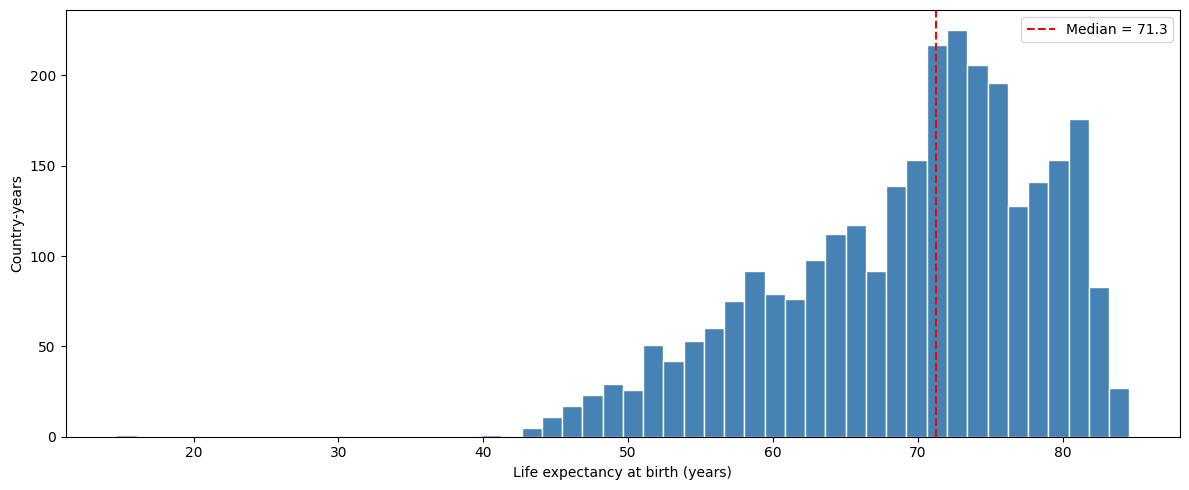

In [43]:
Path("figures").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(sample["lifeexp"], bins=50, color="steelblue", edgecolor="white")
ax.axvline(sample["lifeexp"].median(), color="red", linestyle="--", label=f"Median = {sample['lifeexp'].median():.1f}")
ax.set_xlabel("Life expectancy at birth (years)")
ax.set_ylabel("Country-years")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig1_life_expectancy.png", dpi=150, bbox_inches="tight")
plt.show()
low = sample[sample["lifeexp"] < 50]
low_regions = [(r, int(n)) for r, n in low.groupby("region")["country"].nunique().items()]

*Figure 1. Life expectancy is skewed left because 16 countries fall below 50 years in some years and the median is 71.3 years.*

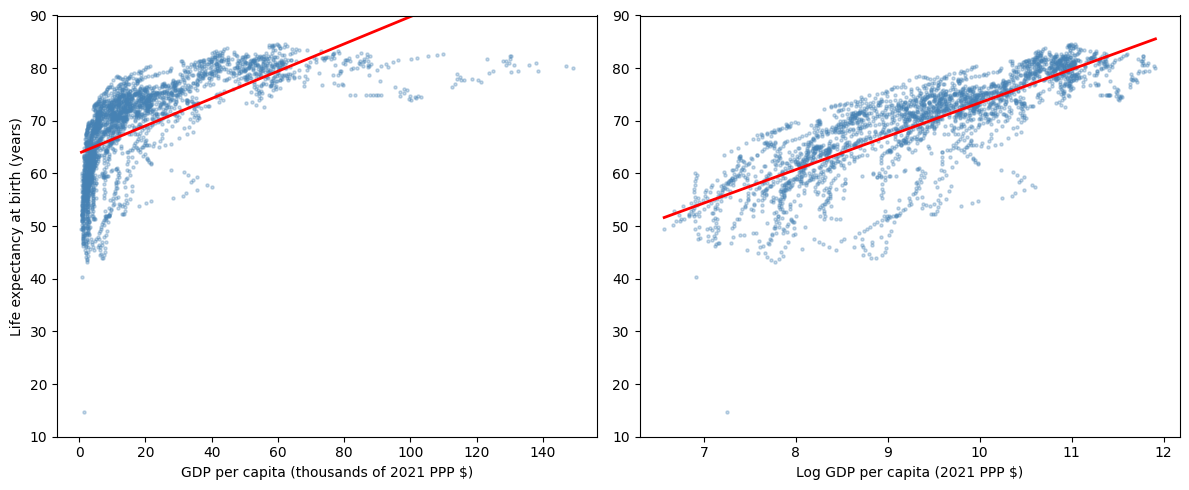

In [27]:
line_dollars = sm.OLS(sample["lifeexp"], sm.add_constant(sample["gdppc"])).fit()
line_logs = sm.OLS(sample["lifeexp"], sm.add_constant(sample["log_gdppc"])).fit()
xs = np.linspace(sample["gdppc"].min(), sample["gdppc"].max(), 100)
log_xs = np.linspace(sample["log_gdppc"].min(), sample["log_gdppc"].max(), 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(sample["gdppc"] / 1000, sample["lifeexp"], s=5, alpha=0.3, color="steelblue")
axes[0].plot(xs / 1000, line_dollars.params["const"] + line_dollars.params["gdppc"] * xs, color="red", linewidth=2)
axes[0].set_xlabel("GDP per capita (thousands of 2021 PPP $)")
axes[0].set_ylabel("Life expectancy at birth (years)")
axes[0].set_ylim(10, 90)
axes[1].scatter(sample["log_gdppc"], sample["lifeexp"], s=5, alpha=0.3, color="steelblue")
axes[1].plot(log_xs, line_logs.params["const"] + line_logs.params["log_gdppc"] * log_xs, color="red", linewidth=2)
axes[1].set_xlabel("Log GDP per capita (2021 PPP $)")
axes[1].set_ylim(10, 90)
plt.tight_layout()
plt.savefig("figures/fig2_preston_curve.png", dpi=150, bbox_inches="tight")
plt.show()

*Figure 2. Life expectancy rises faster with income in poorer countries and levels off in richer ones so log GDP (right) fits the pattern better than GDP in dollars (left).*

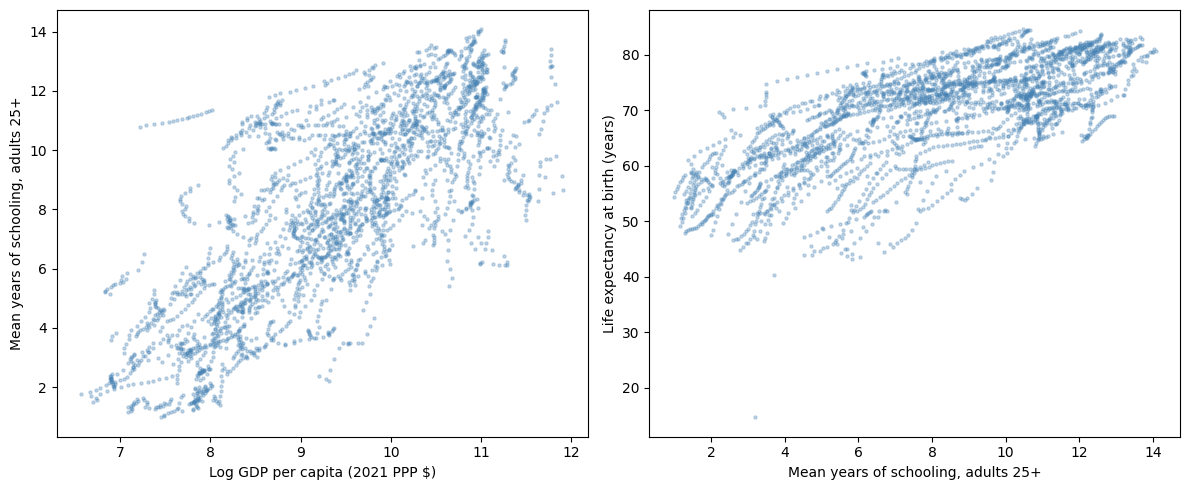

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(sample["log_gdppc"], sample["schooling"], s=5, alpha=0.3, color="steelblue")
axes[0].set_xlabel("Log GDP per capita (2021 PPP $)")
axes[0].set_ylabel("Mean years of schooling, adults 25+")
axes[1].scatter(sample["schooling"], sample["lifeexp"], s=5, alpha=0.3, color="steelblue")
axes[1].set_xlabel("Mean years of schooling, adults 25+")
axes[1].set_ylabel("Life expectancy at birth (years)")
plt.tight_layout()
plt.savefig("figures/fig3_schooling.png", dpi=150, bbox_inches="tight")
plt.show()

*Figure 3. Countries with more schooling tend to be richer (left) and live longer (right) so schooling may help explain the link between GDP and life expectancy.*

Figure 1 shows life expectancy is skewed left with a skew of -0.70 and a log would make a left skew worse so I'll keep life expectancy in years and report the median beside the mean, and Figures 2 and 3 show why the model uses log GDP per capita and holds schooling fixed.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [29]:
def design(data, columns, country_dummies=False):
    parts = {}
    for column in columns:
        parts[column] = data[column]
    for year in YEARS[1:]:
        parts[f"y{year}"] = (data["year"] == year).astype(float)
    if country_dummies:
        for iso in sorted(data["iso3"].unique())[1:]:
            parts[iso] = (data["iso3"] == iso).astype(float)
    return sm.add_constant(pd.DataFrame(parts))


with_health = sample[sample["health_share"] > 0]
labels = sample["iso3"]
labels_health = with_health["iso3"]
X1 = design(sample, ["log_gdppc"])
X2 = design(sample, ["log_gdppc", "schooling"])
X3 = design(with_health, ["log_gdppc", "schooling"])
X4 = design(with_health, ["log_gdppc", "schooling", "health_share"])
X5 = design(sample, ["log_gdppc", "schooling"], country_dummies=True)
m1 = sm.OLS(sample["lifeexp"], X1).fit(cov_type="cluster", cov_kwds={"groups": labels}, use_t=True)
m2 = sm.OLS(sample["lifeexp"], X2).fit(cov_type="cluster", cov_kwds={"groups": labels}, use_t=True)
m3 = sm.OLS(with_health["lifeexp"], X3).fit(cov_type="cluster", cov_kwds={"groups": labels_health}, use_t=True)
m4 = sm.OLS(with_health["lifeexp"], X4).fit(cov_type="cluster", cov_kwds={"groups": labels_health}, use_t=True)
m5 = sm.OLS(sample["lifeexp"], X5).fit(cov_type="cluster", cov_kwds={"groups": labels}, use_t=True)
TERMS = {"log_gdppc": "Log GDP per capita", "schooling": "Mean years of schooling (years)",
         "health_share": "Health spending (% of gov. spending)", "const": "Constant"}
names = ["(1) GDP only", "(2) Main", "(3) Main, health rows", "(4) Adds health share", "(5) Country dummies"]
fits = [m1, m2, m3, m4, m5]
rows = []
for term in TERMS:
    coef_row = {"Term": TERMS[term]}
    se_row = {"Term": ""}
    for name, m in zip(names, fits):
        coef_row[name] = ""
        se_row[name] = ""
        if term in m.params.index:
            coef_row[name] = f"{m.params[term]:.2f}"
            se_row[name] = f"({m.bse[term]:.2f})"
    rows.append(coef_row)
    rows.append(se_row)
for label, values in [("Country dummies", ["No", "No", "No", "No", "Yes"]),
                      ("N", [str(int(m.nobs)) for m in fits]), ("R²", [f"{m.rsquared:.2f}" for m in fits])]:
    row = {"Term": label}
    for name, value in zip(names, values):
        row[name] = value
    rows.append(row)
table_a1 = pd.DataFrame(rows).set_index("Term")
table_a1

,(1) GDP only,(2) Main,"(3) Main, health rows",(4) Adds health share,(5) Country dummies
Term,,,,,
Log GDP per capita,6.29,4.93,4.84,4.58,2.19
,(0.27),(0.42),(0.41),(0.40),(0.71)
Mean years of schooling (years),,0.66,0.67,0.55,-0.03
,,(0.16),(0.15),(0.15),(0.19)
Health spending (% of gov. spending),,,,0.26,
,,,,(0.08),
Constant,9.16,16.96,17.78,18.39,40.36
,(2.65),(3.07),(2.96),(2.85),(5.40)
Country dummies,No,No,No,No,Yes


In [30]:
LN2 = np.log(2)
b = m2.params["log_gdppc"]
lo, hi = m2.conf_int().loc["log_gdppc"]
print(f"Main model: one more unit of log GDP per capita -> {b:.2f} years (95% CI {lo:.2f} to {hi:.2f})")
print(f"Twice the GDP per capita -> {b * LN2:.2f} years (95% CI {lo * LN2:.2f} to {hi * LN2:.2f})")
print(f"One more year of adults' schooling -> {m2.params['schooling']:.2f} years")
print(f"GDP only, no schooling: {m1.params['log_gdppc']:.2f}   Country dummies: {m5.params['log_gdppc']:.2f}")
print(f"Log GDP without and with the health share: {m3.params['log_gdppc']:.2f} and {m4.params['log_gdppc']:.2f}")

Main model: one more unit of log GDP per capita -> 4.93 years (95% CI 4.10 to 5.75)
Twice the GDP per capita -> 3.41 years (95% CI 2.84 to 3.99)
One more year of adults' schooling -> 0.66 years
GDP only, no schooling: 6.29   Country dummies: 2.19
Log GDP without and with the health share: 4.84 and 4.58


**Roles of the controls.** Year dummies block a confounding path because better medicine raised life expectancy and world growth raised GDP almost everywhere at once and GDP can't change the year so they can't be a bad control. Adults' schooling blocks a confounding path because education raises earnings and helps people stay healthy but it would be a bad control if past income paid for that schooling. The health spending share was kept out of the main model because GDP changes it so it sits on the path from GDP to life expectancy as a mediabtor and a bad control and I only add it in column 4. Country dummies in column 5 block every trait a country keeps over time and GDP can't change those traits so they aren't a bad control but they change the question to whether a country lives longer when it grows richer than its own average.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

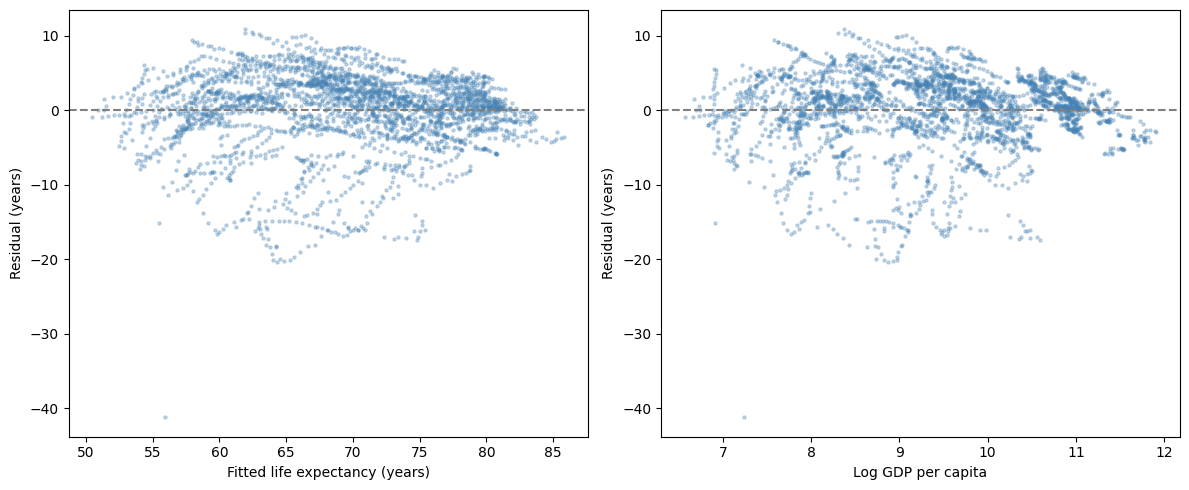

Breusch-Pagan p = 3.07e-09
Log GDP standard error: classical 0.12, clustered 0.42


In [31]:
ols2 = sm.OLS(sample["lifeexp"], X2).fit()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(ols2.fittedvalues, ols2.resid, s=5, alpha=0.3, color="steelblue")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_xlabel("Fitted life expectancy (years)")
axes[0].set_ylabel("Residual (years)")
axes[1].scatter(sample["log_gdppc"], ols2.resid, s=5, alpha=0.3, color="steelblue")
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Log GDP per capita")
axes[1].set_ylabel("Residual (years)")
plt.tight_layout()
plt.savefig("figures/figA1_residuals.png", dpi=150, bbox_inches="tight")
plt.show()
bp = het_breuschpagan(ols2.resid, ols2.model.exog)
print(f"Breusch-Pagan p = {bp[1]:.2e}")
print(f"Log GDP standard error: classical {ols2.bse['log_gdppc']:.2f}, clustered {m2.bse['log_gdppc']:.2f}")

In [32]:
vif = {}
for i, name in enumerate(X2.columns):
    if name in ["log_gdppc", "schooling"]:
        vif[name] = f"{variance_inflation_factor(X2.values, i):.2f}"
print("VIF:", vif)
sample["cooks"] = ols2.get_influence().cooks_distance[0]
cutoff = 4 / len(sample)
big = sample["cooks"] > cutoff
by_country = [(c, int(n)) for c, n in sample.loc[big, "country"].value_counts().items()]
print(f"Cook's distance above {cutoff:.4f}: {big.sum()} rows in {sample.loc[big, 'iso3'].nunique()} countries")
print("Rows by country:", by_country)
kept = sample[sample["cooks"] <= cutoff]
labels_kept = kept["iso3"]
X_kept = design(kept, ["log_gdppc", "schooling"])
m2_keep = sm.OLS(kept["lifeexp"], X_kept).fit(cov_type="cluster", cov_kwds={"groups": labels_kept}, use_t=True)
print(f"Without them: {m2_keep.params['log_gdppc']:.2f} (SE {m2_keep.bse['log_gdppc']:.2f}, N = {int(m2_keep.nobs)})")

VIF: {'log_gdppc': '2.38', 'schooling': '2.40'}
Cook's distance above 0.0014: 144 rows in 16 countries
Rows by country: [('Equatorial Guinea', 16), ('Nigeria', 16), ('Eswatini', 16), ('Botswana', 15), ('Lesotho', 15), ('Namibia', 14), ('Zimbabwe', 13), ('South Africa', 12), ('Angola', 10), ('Sierra Leone', 5), ('Zambia', 3), ('Russian Federation', 3), ('Central African Republic', 2), ('Viet Nam', 2), ('Haiti', 1), ('China', 1)]
Without them: 4.98 (SE 0.32, N = 2760)


The residuals against fitted values and against log GDP show no curve so a straight line in log GDP is enough and Breusch-Pagan rejects constant variance so I use robust standard errors clustered by country because each country shows up as many as 16 times. Clustering increases the GDP standard error from 0.12 to 0.42 but its 95% CI still stays far from zero, and the variance inflation factors are about 2.4 so collinearity isn't a problem and dropping the 144 influential rows that Cook's distance flags barely changes the GDP coefficient.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

For my main coefficient to be causal nothing else that moves life expectancy can vary with GDP once I hold schooling and the year fixed and life expectancy can't feed back into GDP. That doesn't hold because geography and disease and war affect both and healthier workers also earn more and the coefficient falls from 4.93 to 2.19 once I add country dummies so my estimate is a conditional association. I found that a country with twice the GDP per capita lives 3.41 years longer holding schooling and the year fixed (95% CI 2.84 to 3.99 with N = 2,904), and a reader should be confident about this link across countries but much less confident that raising one country's income would add that much because within a country doubling GDP  only adds 1.52 more years. With another month I'd use GDP from ten years earlier to cut the feedback from health to income and add measures of disease and HIV.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [33]:
display(table_a1)

,(1) GDP only,(2) Main,"(3) Main, health rows",(4) Adds health share,(5) Country dummies
Term,,,,,
Log GDP per capita,6.29,4.93,4.84,4.58,2.19
,(0.27),(0.42),(0.41),(0.40),(0.71)
Mean years of schooling (years),,0.66,0.67,0.55,-0.03
,,(0.16),(0.15),(0.15),(0.19)
Health spending (% of gov. spending),,,,0.26,
,,,,(0.08),
Constant,9.16,16.96,17.78,18.39,40.36
,(2.65),(3.07),(2.96),(2.85),(5.40)
Country dummies,No,No,No,No,Yes


## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [34]:
REPORT_NUMBERS = {
    "Box: country-years and countries in the sample": f"{len(sample):,} and {sample['iso3'].nunique()}",
    "Box: World Bank economy-years": f"{len(df):,}",
    "Section 1: economies outside UNDP's list": outside["iso3"].nunique(),
    "Section 1: UNDP countries and those not in the sample":
        f"{undp['iso3'].nunique()} and {undp_dropped['country'].nunique()}",
    "Table 1": "\n" + table1.to_string(index=False),
    "Table 2": "\n" + table2.round(2).to_string(),
    "Table 2: GDP per capita row in whole dollars": table2.loc["GDP per capita (2021 PPP $)"].round(0).tolist(),
    "Section 2: skew, median and mean of life expectancy":
        f"{sample['lifeexp'].skew():.2f}, {sample['lifeexp'].median():.1f}, {sample['lifeexp'].mean():.1f}",
    "Section 2: countries below 50 and their regions": f"{low['country'].nunique()} {low_regions}",
    "Section 2: R-squared of a straight line on dollars and log dollars":
        f"{line_dollars.rsquared:.2f} and {line_logs.rsquared:.2f}",
    "Section 2: corr(schooling, log GDP) and corr(schooling, life expectancy)":
        f"{sample['schooling'].corr(sample['log_gdppc']):.2f} and {sample['schooling'].corr(sample['lifeexp']):.2f}",
    "Section 3: log GDP, SE and 95% CI": f"{b:.2f}, {m2.bse['log_gdppc']:.2f}, {lo:.2f} to {hi:.2f}",
    "Section 3: ln 2": f"{LN2:.3f}",
    "Section 3: years per doubling and 95% CI": f"{b * LN2:.2f}, {lo * LN2:.2f} to {hi * LN2:.2f}",
    "Section 3: schooling, SE and 95% CI":
        f"{m2.params['schooling']:.2f}, {m2.bse['schooling']:.2f}, "
        f"{m2.conf_int().loc['schooling'][0]:.2f} to {m2.conf_int().loc['schooling'][1]:.2f}",
    "Section 3: column 1 log GDP, 95% CI and per doubling":
        f"{m1.params['log_gdppc']:.2f}, {m1.conf_int().loc['log_gdppc'][0]:.2f} to "
        f"{m1.conf_int().loc['log_gdppc'][1]:.2f}, {m1.params['log_gdppc'] * LN2:.2f}",
    "Section 3: R-squared columns 1 and 2": f"{m1.rsquared:.2f} and {m2.rsquared:.2f}",
    "Section 3: rows with a health share": int(m3.nobs),
    "Section 3: log GDP columns 3 and 4": f"{m3.params['log_gdppc']:.2f} and {m4.params['log_gdppc']:.2f}",
    "Section 3: column 5 log GDP and 95% CI":
        f"{m5.params['log_gdppc']:.2f}, {m5.conf_int().loc['log_gdppc'][0]:.2f} to "
        f"{m5.conf_int().loc['log_gdppc'][1]:.2f}",
    "Section 3: column 5 per doubling and 95% CI":
        f"{m5.params['log_gdppc'] * LN2:.2f}, {m5.conf_int().loc['log_gdppc'][0] * LN2:.2f} to "
        f"{m5.conf_int().loc['log_gdppc'][1] * LN2:.2f}",
    "Section 4: Breusch-Pagan p": f"{bp[1]:.2e}",
    "Section 4: standard errors classical and clustered": f"{ols2.bse['log_gdppc']:.2f} and {m2.bse['log_gdppc']:.2f}",
    "Section 4: VIF": vif,
    "Section 4: Cook's cutoff, rows and countries": f"{cutoff:.4f}, {big.sum()}, {sample.loc[big, 'iso3'].nunique()}",
    "Section 4: largest Cook's distance":
        sample.nlargest(1, "cooks")[["country", "year", "cooks"]].round(3).values.tolist(),
    "Section 4: without them, SE and N":
        f"{m2_keep.params['log_gdppc']:.2f}, {m2_keep.bse['log_gdppc']:.2f}, {int(m2_keep.nobs):,}",
    "Table A1": "\n" + table_a1.to_string(),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Box: country-years and countries in the sample: 2,904 and 186
Box: World Bank economy-years: 3,472
Section 1: economies outside UNDP's list: 22
Section 1: UNDP countries and those not in the sample: 195 and 9
Table 1: 
                                    Step  Rows
Economies x years, World Bank, 2000-2015  3472
                      No life expectancy     0
                 No GDP per capita (PPP)  -341
              No mean years of schooling  -227
             Country-years in the sample  2904
Table 2: 
                                                           Mean    Median        SD      Min        Max     N
Variable (units)                                                                                             
Life expectancy at birth (years)                          69.36     71.26      9.11    14.66      84.60  2904
GDP per capita (2021 PPP $)                            21207.06  12395.94  23285.16   711.98  149025.12  2904
Log GDP per capita                               

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.